In [7]:
# Exécuter cette cellule pour installer MLflow dans le conteneur Jupyter
!pip install mlflow

   ---------------------------------------- 0.0/10.5 MB ? eta -:--:--
   - -------------------------------------- 0.3/10.5 MB ? eta -:--:--
   -- ------------------------------------- 0.5/10.5 MB 2.4 MB/s eta 0:00:05
   ---- ----------------------------------- 1.0/10.5 MB 1.7 MB/s eta 0:00:06
   ----- ---------------------------------- 1.3/10.5 MB 1.7 MB/s eta 0:00:06
   ------- -------------------------------- 1.8/10.5 MB 1.8 MB/s eta 0:00:05
   -------- ------------------------------- 2.1/10.5 MB 1.8 MB/s eta 0:00:05
   --------- ------------------------------ 2.4/10.5 MB 1.7 MB/s eta 0:00:05
   ----------- ---------------------------- 2.9/10.5 MB 1.8 MB/s eta 0:00:05
   -------------- ------------------------- 3.7/10.5 MB 1.9 MB/s eta 0:00:04
   --------------- ------------------------ 3.9/10.5 MB 1.9 MB/s eta 0:00:04
   ---------------- ----------------------- 4.2/10.5 MB 1.9 MB/s eta 0:00:04
   ------------------ --------------------- 4.7/10.5 MB 1.9 MB/s eta 0:00:04
   ----------


[notice] A new release of pip is available: 26.0.1 -> 26.1
[notice] To update, run: C:\Users\MSI\anaconda3\python.exe -m pip install --upgrade pip


In [8]:
# Cellule 1 : Imports et Données Historiques
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta

# Simuler les logs de 7 jours de serveur Harmony
np.random.seed(42)
n_logs = 1000
hours = np.random.randint(0, 24, n_logs)
requests = np.random.poisson(lam=50 + (hours * 5), size=n_logs) # Plus de traffic l'après-midi/soir
cpu_usage = requests * 0.4 + np.random.normal(0, 5, n_logs)
cost = (cpu_usage / 100) * 0.10 # Coût CPU simulé

df_logs = pd.DataFrame({
    'timestamp': [datetime.now() - timedelta(hours=int(x)) for x in hours],
    'hour_of_day': hours,
    'requests_per_sec': requests,
    'cpu_usage': cpu_usage,
    'estimated_cost_eur': cost
})

df_logs.head()

,timestamp,hour_of_day,requests_per_sec,cpu_usage,estimated_cost_eur
0,2026-04-30 06:01:07.358215,6,67,27.836337,0.027836
1,2026-04-29 17:01:07.358215,19,137,55.146722,0.055147
2,2026-04-29 22:01:07.358215,14,107,39.191312,0.039191
3,2026-04-30 02:01:07.358215,10,101,41.284104,0.041284
4,2026-04-30 05:01:07.358215,7,80,29.266600,0.029267


In [9]:
# Cellule 2 : Corrélation et Insights
# L'Agent Analyste cherche la relation entre Requests et CPU
correlation = df_logs[['requests_per_sec', 'cpu_usage']].corr()
print("Matrice de corrélation :\n", correlation)

print("\nStatistiques clés pour l'agent Optimiseur :")
print(f"Coût total estimé : {df_logs['estimated_cost_eur'].sum():.2f} EUR")
print(f"Heure de pic moyen : {df_logs.groupby('hour_of_day')['requests_per_sec'].mean().idxmax()}h")

Matrice de corrélation :
                   requests_per_sec  cpu_usage
requests_per_sec          1.000000   0.945806
cpu_usage                 0.945806   1.000000

Statistiques clés pour l'agent Optimiseur :
Coût total estimé : 42.78 EUR
Heure de pic moyen : 23h


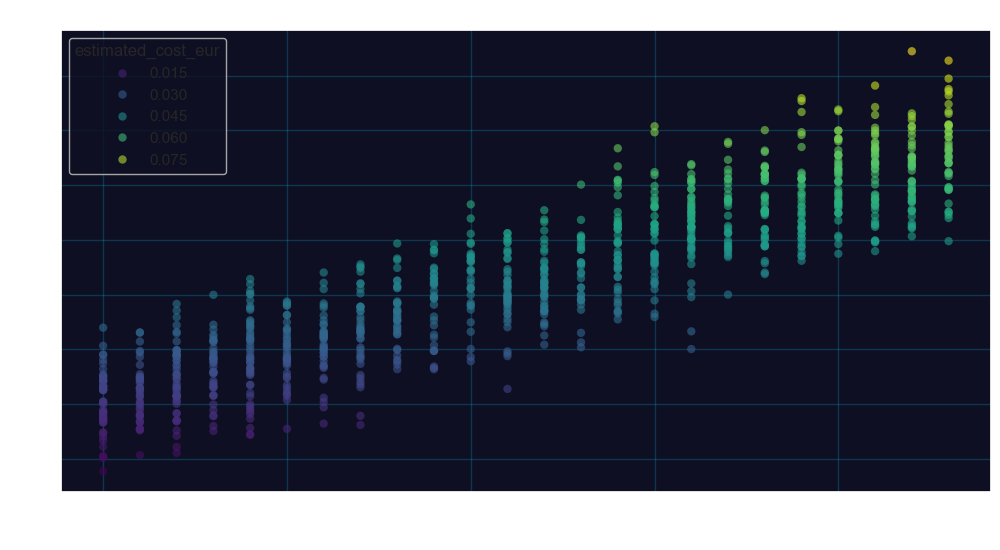

In [10]:
# Cellule 3 : Visualisation du Trafic (Style Harmony)
plt.figure(figsize=(12, 6))

# CORRECTION : Utilisation d'un tuple RGBA (Rouge, Vert, Bleu, Alpha) pour la grille
# (0.0, 0.85, 1.0, 0.2) correspond à #00d9ff avec 20% d'opacité
sns.set_theme(style="darkgrid", rc={
    "axes.facecolor": "#0f0f23", 
    "grid.color": (0.0, 0.85, 1.0, 0.2) 
})

sns.scatterplot(data=df_logs, x='hour_of_day', y='cpu_usage', hue='estimated_cost_eur', 
                palette='viridis', alpha=0.6, edgecolor='none')

plt.title('Analyse Agent: Charge CPU vs Heure de la journée', color='white')
plt.xlabel('Heure de la journée', color='white')
plt.ylabel('Usage CPU (%)', color='white')
plt.tick_params(colors='white')
plt.show()